<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/%C3%B6dev4_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

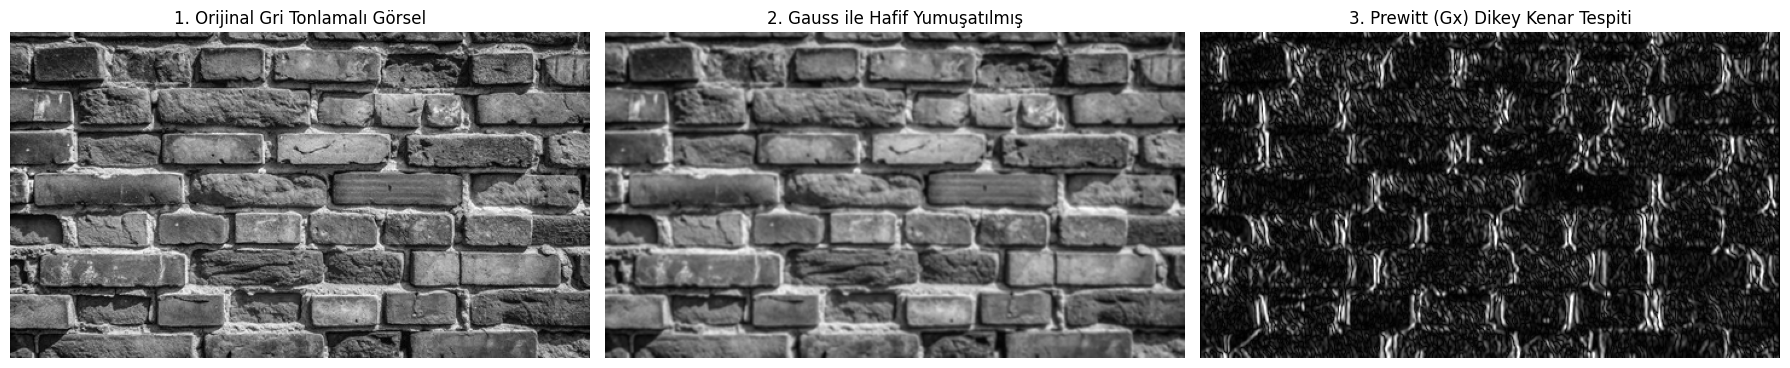

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Görseli gri tonlamalı (grayscale) olarak yükle
image_path = 'tugla_duvar.jpeg'
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError(f"'{image_path}' dosyası bulunamadı. Lütfen sol panelden yüklediğiniz dosya adını kontrol edin.")

# 2. Tuğla yüzeyindeki mikro pürüzleri ve gürültüyü bastırmak için hafif Gauss filtresi uygula
# (3x3 çekirdek boyutu ve sigmaX=1.0)
blurred_image = cv2.GaussianBlur(image, (3, 3), sigmaX=1.0)

# 3. 3x3 Prewitt Dikey Kenar Filtresi (Gx) Tanımı
# [[-1, 0, 1],
#  [-1, 0, 1],
#  [-1, 0, 1]]
prewitt_kernel = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

# 4. Konvolüsyon işlemini gerçekleştir (Negatif gradyanları korumak için CV_64F kullanılır)
prewitt_edges = cv2.filter2D(blurred_image, cv2.CV_64F, prewitt_kernel)

# 5. Görselleştirme için mutlak değeri al ve 8-bit (0-255) aralığına sınırla
abs_edges = np.absolute(prewitt_edges)
output_image = np.uint8(np.clip(abs_edges, 0, 255))

# 6. Aşamaları ve sonuçları yan yana görselleştir
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.title("1. Orijinal Gri Tonlamalı Görsel", fontsize=12)
plt.imshow(image, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("2. Gauss ile Hafif Yumuşatılmış", fontsize=12)
plt.imshow(blurred_image, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("3. Prewitt (Gx) Dikey Kenar Tespiti", fontsize=12)
plt.imshow(output_image, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()